# 03 GPU Cost Scenarios

Recomputes transparent small, medium, and large workloads. Costs are standardized scenarios, not estimates of confidential company spending.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd()
assert (ROOT / "data").exists(), "Execute with project root as the working directory."
pd.set_option("display.max_colwidth", 120)


In [2]:
cost=pd.read_csv(ROOT/"data/cleaned/fact_training_cost_scenario.csv")
components=["training_compute_cost_usd","simulation_compute_cost_usd","base_storage_cost_usd","checkpoint_storage_cost_usd","egress_cost_usd"]
cost["recomputed_total"]=cost[components].sum(axis=1)
float((cost.total_cost_usd-cost.recomputed_total).abs().max())

4.656612873077393e-10

In [3]:
on_demand=cost[cost.discount_model=="On-demand"]
best=on_demand.loc[on_demand.groupby("scenario_name").total_cost_usd.idxmin(),
                   ["scenario_name","cloud_provider","instance_type","gpu_model","total_cost_usd"]]
best.sort_values("total_cost_usd")

,scenario_name,cloud_provider,instance_type,gpu_model,total_cost_usd
9,Small experimentation,Microsoft Azure,Standard_NC24ads_A100_v4,A100 80GB,1.227179e+03
27,Medium development,Microsoft Azure,Standard_NC24ads_A100_v4,A100 80GB,1.097060e+05
45,Large AV training,Microsoft Azure,Standard_NC24ads_A100_v4,A100 80GB,2.858251e+06


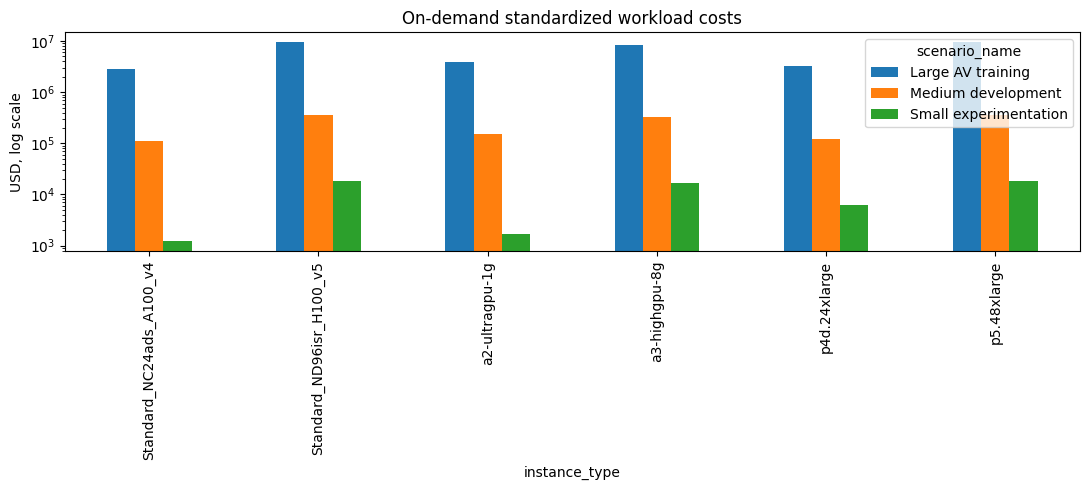

In [4]:
pivot=on_demand.pivot(index="instance_type",columns="scenario_name",values="total_cost_usd")
ax=pivot.plot(kind="bar",figsize=(11,5))
ax.set_yscale("log")
ax.set_ylabel("USD, log scale")
ax.set_title("On-demand standardized workload costs")
plt.tight_layout()
plt.show()

In [5]:
sens=pd.read_csv(ROOT/"data/reporting/gpu_cost_sensitivity.csv")
sens[sens.scenario_name=="Large AV training"].groupby("variable").change_from_baseline_pct.agg(["min","max"]).sort_values("max",ascending=False)

,min,max
variable,,
GPU hours,-41.764811,83.529622
Number of experiments,-41.764811,83.529622
Utilization,-10.382687,69.044870
Storage volume,-0.482813,0.965626
Data egress price,-0.157439,0.157439
Pricing factor,-54.249541,0.000000
